## HW6

### Hyeonseo Daniel Kim

Plot the x-t diagram for a sudden expansion wave. Take a tube whose initial length is given as 5 meters filled with air at 101325 Pa and 300 K. At time t = 0 one of the endcaps moves away from the other endcap at a constant speed of 100 m/s. Plot graphically the characteristics associated with the expansion fan as it emanates from from the sudden expansion corner in the x-t diagram and subsequently interacts with its reflection coming from the second stationary endcap

### Part 1 : Incident part of expansion Wave 
<img src="https://github.com/DanielKim0208/ME-433RocketScience/blob/main/HW6/Fig%207.15.png?raw=true" width="500" alt="Fig 7.3"> <Br>

In the image, <br>
$(J_+)_a = (J_+)_b$ <br>
$(J_+)_a = (J_+)_c = (J_+)_e$ <br>
$(J_+)_b = (J_+)_d = (J_+)_f$ <br>

where 

$$J_+ = u + \frac{2a}{\gamma - 1} = Const $$
$$J_- = u - \frac{2a}{\gamma - 1} = Const $$

In the given problem, for the head, <br>
u = u_4 = 0 <br> 
u_p = u_3 = 100 <br>

linspacing u_p from 100 to 0 by given n increments...






347.18870949384285
[[0, np.float64(0.014401389974026995), np.float64(0.0), np.float64(347.18870949384285), np.float64(1735.9435474692145), np.float64(-1735.9435474692145)], [1, np.float64(0.016276639881194), np.float64(33.333333333333336), np.float64(340.52204282717616), np.float64(1702.6102141358813), np.float64(-1669.276880802548)], [2, np.float64(0.018713365581472005), np.float64(66.66666666666667), np.float64(333.8553761605095), np.float64(1669.2768808025478), np.float64(-1602.610214135881)], [3, np.float64(0.0220081359286717), np.float64(100.0), np.float64(327.18870949384285), np.float64(1635.9435474692145), np.float64(-1535.9435474692145)]]
(np.float64(33.33333333333326), np.float64(340.52204282717616))
0.0027775545354049506


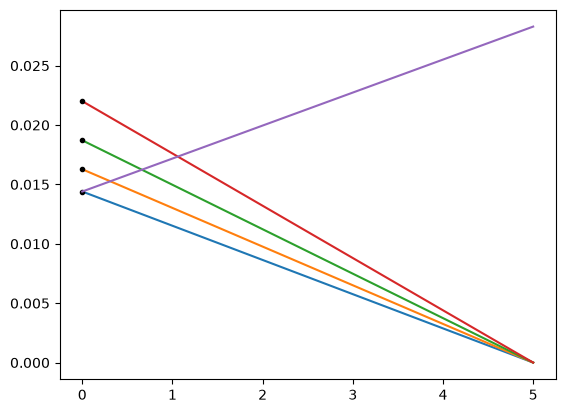

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

#Problem given
gamma = 1.4 
R= 287 
P_init = 101325 
T_init  = 300 
u_p = 100

#Number of rays = 50
n_rays = 4

# 0 to piston speed, divide into n rays
u = np.linspace(0,u_p, n_rays)
u_4 = 0

x_init, y_init = 5.0, 0.0
x_wall = 0.0
x_linspace = np.linspace(0,5,100)

incident = []
incident_wall = []

a_4 = np.sqrt( gamma * R * T_init)
print(a_4)

fig,ax = plt.subplots()

def incidentray(u, a):
    m = 1 / (u - a)
    y_wall = y_init + m * (x_wall - x_init)
    return y_wall, m

#Jplus hardcoded to be identical across incident rays, J minus changes 
J_plus_incident = u_4 + (2 * a_4)/(gamma -1)
for i in u:

    a_i = ((J_plus_incident - i)*(gamma - 1))/2 
    J_minus_incident = i - (2*a_i)/(gamma -1)
    _, m_i = incidentray(u,a_i)
    incident.append([i, a_i, m_i, J_plus_incident, J_minus_incident])


for idx, (u, a, m_i, J_plus, J_minus) in enumerate(incident): 
    y_wall_i, _ = incidentray(u,a)
    ax.plot([x_init, x_wall], [y_init, y_wall_i ])
    J_plus_wall = ((2*a)/(gamma - 1)) # + u_wall = 0
    incident_wall.append([idx, y_wall_i, u, a, J_plus_wall, J_minus])

print(incident_wall)
for idx, y_wall_i, u, a, J_plus_wall, J_minus in incident_wall: 
    ax.plot(x_wall, y_wall_i, '.', color = "black")

#fig.show()

# 5, 8 , 10 has direction = negative 
# Others have direction = Positive 
def correctvalues(Jplus, Jminus):
    u = 0.5 * (Jplus + Jminus)
    a = (gamma - 1) / 4 * (Jplus - Jminus)
    return u, a

def marching(direction, u1, a1, u2, a2): 
    if direction == "right":
        theta1 = np.arctan2(1, u1 + a1)
        theta2 = np.arctan2(1, u2 + a2)
    elif direction == "left": 
        theta1 = np.arctan2(1, u1 - a1)
        theta2 = np.arctan2(1, u2 - a2)   
    m_avg = np.tan(0.5 * (theta1 + theta2))
    return m_avg

#    incident_wall.append([idx, y_wall_i, u, a, J_plus_wall, J_minus])

J_plus  = incident_wall[0][4]   # idx = 1
J_minus = incident_wall[1][5]   # idx = 2
print(correctvalues(J_plus, J_minus))
#This value is same as the 2 value above, since there hasn't been any reflection modelled yet 

u_1, a_1 = incident_wall[0][2], incident_wall[0][3]
u_2, a_2 = correctvalues(J_plus,J_minus)

m_12 = marching("right", u_1, a_1, u_2, a_2)
print(m_12)

y_12 = incident_wall[0][1] + m_12*x_linspace

ax.plot(x_linspace,y_12)

plt.show()



Significant part of the data in each index of incident_wall is wrong. <br><br>
all data for the first point is correct. <br>
All J minus of the curve is correct. <br>
At the current wall points, u = 0. <br>
I can update the u values <br>

I can find correct a  with J_minus <br>
I can update the index with the correct a <br>
Based on correct u and a, I can find correct J_plus numbers <br>
I can update the index with the correct J_plus numbers

For point 2, there hasn't been interaction yet. <br>
slope can be calculated with J+ and J- value as-is 

<img src="https://github.com/DanielKim0208/ME-433RocketScience/blob/main/HW6/Fig%207.16.png?raw=true" width="500" alt="Fig 7.3"> <Br>
<img src="https://github.com/DanielKim0208/ME-433RocketScience/blob/main/HW6/Nonsimple%20Region%20Relations.png?raw=true
" width="500" alt="Fig 7.3"> <Br>



